# 02 · V1 baseline: plain cross-entropy on one state cannot recover the rule

**What this notebook shows.** The simplest possible model, and why it is not enough. An MLP sees one state (19 numbers), predicts the action, pick and drop, and is trained with plain cross-entropy. It is never given eps and never sees history.

**Results (recorded run on the full dataset).**
- Pick and drop are learned perfectly (precision and recall 1.000).
- Action loss stays 0.052 above the floor after 2 epochs.
- Accuracy is below the best possible at every eps (test, eps 0.1: 0.646 vs a ceiling of 0.692).
- On clear-choice rows at eps 0.1 the model picks the rule's move 0.855 of the time (test) while the data does 0.925.
- The model agrees with the rule on 0.975 to 0.985 of target-driven rows but only 0.883 to 0.916 of smell-driven rows, and 0.63 to 0.73 when the two strongest smells nearly tie.

**Conclusion.** Plain cross-entropy asks one network to predict "rule plus noise" averaged over all ten eps values, so it learns a blurred version of the rule and cannot separate the two. A single state also carries nothing about *this* ant's eps. Two fixes follow: a loss that separates rule from noise (notebook 03) and history to read eps (notebook 04).

**Note.** This V1 trains on **raw** states, exactly as it was first run, so the numbers above reproduce. Raw smell gaps are tiny, which makes smell-driven rows harder still; notebook 03 fixes the loss and the inputs together.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Data: one row per ant-step

In [2]:
NORMALIZE_INPUTS = False          # V1 as originally run: raw states

flat = {split: flatten(load_split(split), norm=NORMALIZE_INPUTS) for split in ["train", "val", "test"]}
for split, f in flat.items():
    print(f"{split}: {len(f['action']):,} rows")
print("action counts (train):", np.bincount(flat["train"]["action"]))
print(f"pick rate {flat['train']['pick'].mean():.4f}   drop rate {flat['train']['drop'].mean():.4f}")

train: 9,000,000 rows
val: 3,000,000 rows
test: 3,000,000 rows
action counts (train): [2229001 2220072 2285763 2265164]
pick rate 0.0042   drop rate 0.0040


## 2. Model and the two scores we track

- **Ceiling** = the chance of the most likely move, (1 - eps)/k + eps/4 for k tied best directions. No model can beat it on average.
- **Loss above floor** = model cross-entropy minus the floor from notebook 01.

In [3]:
show(MLPBaseline)


def ceiling(s, eps):
    """Best possible accuracy per row: probability of the most likely move."""
    return (1 - eps) / n_ties(s) + eps / N_ACTIONS


@torch.no_grad()
def predict(model, f, batch=65536):
    """Action probabilities and pick/drop decisions for every row."""
    model.eval()
    probs, pick, drop = [], [], []
    for start in range(0, len(f["action"]), batch):
        a_logit, p_logit, d_logit = model(torch.from_numpy(f["state"][start:start + batch]).to(DEVICE))
        probs.append(a_logit.softmax(-1).cpu().numpy())
        pick.append((p_logit > 0).cpu().numpy())
        drop.append((d_logit > 0).cpu().numpy())
    model.train()
    return np.concatenate(probs), np.concatenate(pick), np.concatenate(drop)


def val_check(model, f):
    """Clear-row accuracy at eps 0.1 (target 0.925) and action loss above floor (target 0)."""
    probs, _, _ = predict(model, f)
    s, a, e = f["state"], f["action"], f["eps"]
    m = np.isclose(e, 0.1) & (n_ties(s) == 1)
    acc_k1 = (probs.argmax(1)[m] == a[m]).mean()
    gap = (-np.log(probs[np.arange(len(a)), a] + 1e-12)).mean() - true_entropy(s, e).mean()
    return acc_k1, gap

class MLPBaseline(nn.Module):
    """V1: plain MLP on one state. No eps, no history."""
    def __init__(self, d_in=19, hidden=128):
        super().__init__()
        self.ffn = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU())
        self.action_head = nn.Linear(hidden, N_ACTIONS)
        self.pick_head = nn.Linear(hidden, 1)
        self.drop_head = nn.Linear(hidden, 1)

    def forward(self, x):
        z = self.ffn(x)
        return self.action_head(z), self.pick_head(z).squeeze(-1), self.drop_head(z).squeeze(-1)



## 3. Train (plain cross-entropy, eps never used)

In [4]:
V1_BATCH, V1_LR, LOG_EVERY = 256, 1e-3, 500

model = MLPBaseline().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=V1_LR)
S, A = torch.from_numpy(flat["train"]["state"]), torch.from_numpy(flat["train"]["action"])
P, D = torch.from_numpy(flat["train"]["pick"]), torch.from_numpy(flat["train"]["drop"])

curve, running, n, step = [], 0.0, 0, 0
for epoch in range(1, STEP_EPOCHS + 1):
    perm = torch.randperm(len(A))
    for start in range(0, len(A), V1_BATCH):
        idx = perm[start:start + V1_BATCH]
        a_logit, p_logit, d_logit = model(S[idx].to(DEVICE))
        loss_action = F.cross_entropy(a_logit, A[idx].to(DEVICE))
        loss = (loss_action
                + F.binary_cross_entropy_with_logits(p_logit, P[idx].to(DEVICE))
                + F.binary_cross_entropy_with_logits(d_logit, D[idx].to(DEVICE)))
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        step, running, n = step + 1, running + loss_action.item(), n + 1
        if step % LOG_EVERY == 0:
            curve.append((step, running / n))
            running, n = 0.0, 0
    acc_k1, gap = val_check(model, flat["val"])
    print(f"epoch {epoch}: val clear-row acc at eps 0.1 = {acc_k1:.3f} (target 0.925), "
          f"action loss above floor = {gap:.4f} (target 0)")

train_floor = true_entropy(flat["train"]["state"], flat["train"]["eps"]).mean()

epoch 1: val clear-row acc at eps 0.1 = 0.801 (target 0.925), action loss above floor = 0.0753 (target 0)
epoch 2: val clear-row acc at eps 0.1 = 0.856 (target 0.925), action loss above floor = 0.0559 (target 0)


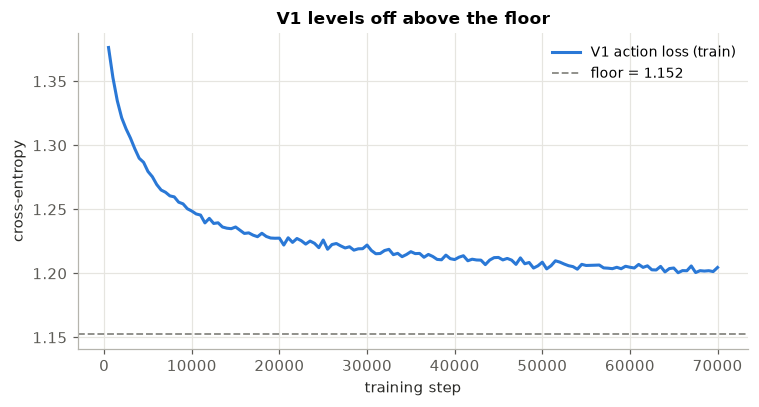

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
if curve:
    steps, losses = zip(*curve)
    ax.plot(steps, losses, color=C["blue"], label="V1 action loss (train)")
ax.axhline(train_floor, color=C["gray"], ls="--", lw=1.2, label=f"floor = {train_floor:.3f}")
ax.set(xlabel="training step", ylabel="cross-entropy", title="V1 levels off above the floor")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** In the recorded run the val clear-row accuracy at eps 0.1 was 0.821 after epoch 1 and 0.858 after epoch 2 (target 0.925), and the loss gap fell from 0.070 to 0.052. Training loss was still drifting down slowly, but the gap that remains is mostly structural: without eps the best this model can do is one average confidence for all ten eps values, and that average cannot reach a floor that assumes eps is known.

## 4. Accuracy vs the best possible, per eps

In [6]:
results = {}
for split in ["val", "test"]:
    f = flat[split]
    probs, pick_pred, drop_pred = predict(model, f)
    results[split] = dict(pred=probs.argmax(1), pick=pick_pred, drop=drop_pred)
    for name, true, guess in [("pick", f["pick"] > 0.5, pick_pred), ("drop", f["drop"] > 0.5, drop_pred)]:
        tp = (true & guess).sum()
        print(f"{split} {name}: precision {tp / max(guess.sum(), 1):.3f}  recall {tp / max(true.sum(), 1):.3f}")

rows = []
for split in ["val", "test"]:
    f, pred = flat[split], results[split]["pred"]
    ceil = ceiling(f["state"], f["eps"])
    for e in EPS_GRID:
        m = np.isclose(f["eps"], e)
        rows.append(dict(split=split, eps=e, accuracy=(pred[m] == f["action"][m]).mean(), ceiling=ceil[m].mean()))
acc = pd.DataFrame(rows).pivot(index="eps", columns="split", values=["accuracy", "ceiling"])
print(acc.round(3))

val pick: precision 1.000  recall 1.000
val drop: precision 1.000  recall 1.000
test pick: precision 1.000  recall 0.998
test drop: precision 1.000  recall 1.000
      accuracy        ceiling       
split     test    val    test    val
eps                                 
0.1      0.635  0.620   0.692  0.662
0.2      0.584  0.566   0.646  0.603
0.3      0.544  0.527   0.607  0.556
0.4      0.521  0.494   0.558  0.525
0.5      0.483  0.440   0.512  0.462
0.6      0.438  0.412   0.463  0.434
0.7      0.375  0.358   0.395  0.376
0.8      0.338  0.308   0.351  0.323
0.9      0.285  0.273   0.294  0.284
1.0      0.250  0.249   0.250  0.250


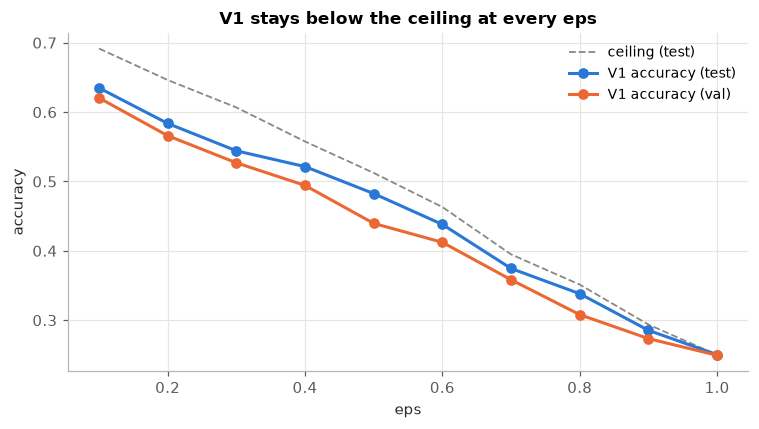

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(EPS_GRID, acc[("ceiling", "test")], color=C["gray"], ls="--", lw=1.2, label="ceiling (test)")
ax.plot(EPS_GRID, acc[("accuracy", "test")], "-o", color=C["blue"], label="V1 accuracy (test)")
ax.plot(EPS_GRID, acc[("accuracy", "val")], "-o", color=C["orange"], label="V1 accuracy (val)")
ax.set(xlabel="eps", ylabel="accuracy", title="V1 stays below the ceiling at every eps")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded test accuracy vs ceiling:

| eps | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |
|---|---|---|---|---|---|---|---|---|---|---|
| V1 (test) | 0.646 | 0.594 | 0.539 | 0.526 | 0.486 | 0.442 | 0.379 | 0.339 | 0.286 | 0.249 |
| ceiling | 0.692 | 0.646 | 0.607 | 0.558 | 0.512 | 0.463 | 0.395 | 0.351 | 0.294 | 0.250 |

The shortfall is largest at low eps (0.05 to 0.07), exactly where the rule matters most. At eps 1.0 every model is at 0.25, since nothing can be predicted.

## 5. On clear-choice rows: model vs data vs theory

       model          data        expected       
split   test    val   test    val     test    val
eps                                              
0.1    0.837  0.856  0.925  0.925    0.925  0.925
0.2    0.751  0.788  0.851  0.850    0.850  0.850
0.3    0.682  0.722  0.774  0.775    0.775  0.775
0.4    0.649  0.649  0.699  0.701    0.700  0.700
0.5    0.582  0.586  0.625  0.627    0.625  0.625
0.6    0.514  0.513  0.549  0.551    0.550  0.550
0.7    0.444  0.442  0.473  0.477    0.475  0.475
0.8    0.380  0.370  0.400  0.399    0.400  0.400
0.9    0.310  0.302  0.327  0.326    0.325  0.325
1.0    0.249  0.247  0.249  0.248    0.250  0.250


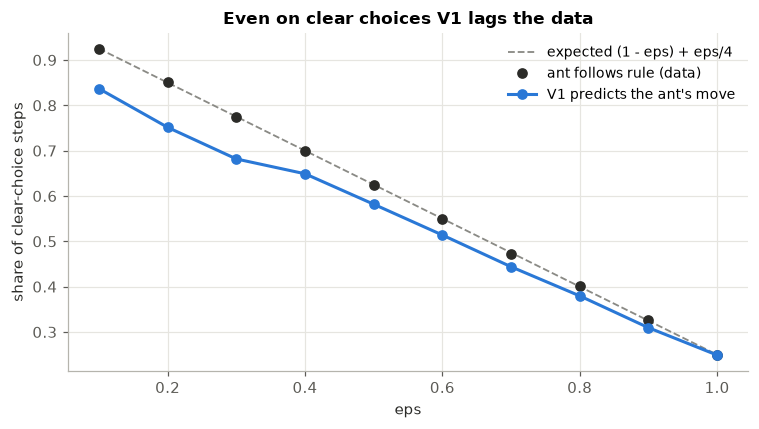

In [8]:
rows = []
for split in ["val", "test"]:
    f, pred = flat[split], results[split]["pred"]
    s, a, e = f["state"], f["action"], f["eps"]
    clear, best = n_ties(s) == 1, best_dir(s)
    for v in EPS_GRID:
        m = clear & np.isclose(e, v)
        rows.append(dict(split=split, eps=v,
                         model=(pred[m] == a[m]).mean(),       # model's guess matches the ant
                         data=(a[m] == best[m]).mean(),        # the ant matches the rule
                         expected=(1 - v) + v / 4))
k1 = pd.DataFrame(rows).pivot(index="eps", columns="split", values=["model", "data", "expected"])
print(k1.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(EPS_GRID, k1[("expected", "test")], color=C["gray"], ls="--", lw=1.2, label="expected (1 - eps) + eps/4")
ax.plot(EPS_GRID, k1[("data", "test")], "o", color=C["ink"], label="ant follows rule (data)")
ax.plot(EPS_GRID, k1[("model", "test")], "-o", color=C["blue"], label="V1 predicts the ant's move")
ax.set(xlabel="eps", ylabel="share of clear-choice steps", title="Even on clear choices V1 lags the data")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** On clear-choice rows the best guess is always the rule's move, so a perfect model would sit on the expected line. Recorded at eps 0.1: data 0.925, V1 0.858 (val) and 0.855 (test); at eps 0.3: data 0.775, V1 0.729 and 0.674. V1 sometimes guesses a different move even when only one move makes sense, meaning it has not learned the rule cleanly.

## 6. Where V1 goes wrong: smell-driven steps

In [9]:
bins = [0, 0.01, 0.03, 0.1, 0.3, 1.01]
labels = ["0-0.01", "0.01-0.03", "0.03-0.1", "0.1-0.3", "0.3+"]
margin_rows = []
for split in ["val", "test"]:
    f, pred = flat[split], results[split]["pred"]
    s = f["state"]                                        # raw states (V1 input)
    clear, best, see = n_ties(s) == 1, best_dir(s), sees_target(s)
    print(f"{split}: agrees with rule  target-driven {(pred[clear & see] == best[clear & see]).mean():.3f}"
          f"   smell-driven {(pred[clear & ~see] == best[clear & ~see]).mean():.3f}")

    m = clear & ~see                                      # smell-driven clear rows
    smell = np.where((s[:, CARRYING] > 0.5)[:, None], s[:, SMELL_HOME], s[:, SMELL_FOOD])[m]
    top2 = np.sort(smell, axis=1)[:, -2:]
    idx = np.digitize(top2[:, 1] - top2[:, 0], bins) - 1  # gap between the two strongest smells
    ok = pred[m] == best[m]
    for i, lab in enumerate(labels):
        sel = idx == i
        if sel.any():
            margin_rows.append(dict(split=split, margin=lab, rows=int(sel.sum()), agree=ok[sel].mean()))

margins = pd.DataFrame(margin_rows)
print()
print(margins.pivot(index="margin", columns="split", values="agree").loc[labels].round(3))
margins[margins.split == "val"].to_csv(OUT_DIR / "v1_margin_agreement.csv", index=False)   # used in notebook 03

val: agrees with rule  target-driven 0.985   smell-driven 0.880
test: agrees with rule  target-driven 0.974   smell-driven 0.869

split       test    val
margin                 
0-0.01     0.634  0.625
0.01-0.03  0.871  0.896
0.03-0.1   0.947  0.944
0.1-0.3    0.950  0.946
0.3+       0.989  0.986


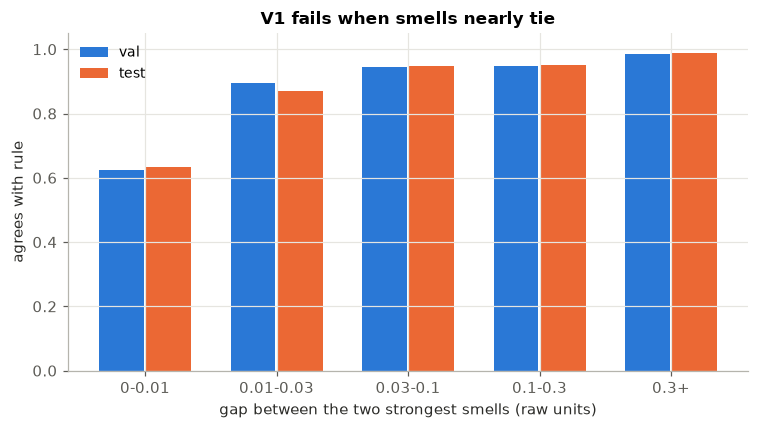

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(labels))
for i, (split, color) in enumerate([("val", C["blue"]), ("test", C["orange"])]):
    part = margins[margins.split == split].set_index("margin").reindex(labels)
    ax.bar(x + (i - 0.5) * 0.36, part.agree, width=0.34, color=color, label=split)
ax.set_xticks(x, labels)
ax.set(xlabel="gap between the two strongest smells (raw units)", ylabel="agrees with rule",
       ylim=(0, 1.05), title="V1 fails when smells nearly tie")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded: target-driven agreement 0.975 (val) and 0.985 (test), smell-driven 0.893 and 0.883. By smell gap, val agreement is 0.626 for gaps below 0.01, 0.912 for 0.01 to 0.03, and about 0.96 above that. Seeing food or home is an easy signal; picking the strongest of four nearly equal raw smells is not, and the blurred loss gives V1 no reason to be sharp there.

**Takeaway for V2.** (1) Tell the loss which part is noise, so the network only has to learn the rule. (2) Give the network only the inputs the rule uses, normalized, and treat the 4 directions alike.